# Inventory policies – CA_1, FOODS_3

Goal: turn the Phase 1 forecasts into weekly orders and measure stock, service and cost
in a day-by-day replay of 2016-01-04 to 2016-05-22.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))

from src.inventory.inputs import build_inputs, draw_lead_times
from src.inventory.policies import replenish_last_week
from src.inventory.simulate import simulate

plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

inputs = build_inputs()
lead_times = draw_lead_times(inputs)
baseline = simulate(inputs, replenish_last_week, lead_times)
baseline.head()

,unique_id,demand_class,sell_price,ds,start_stock,received,demand,sales,lost,end_stock,order,on_order
0,FOODS_3_001_CA_1,intermittent,2.5,2016-01-04,9.0,0.0,1.0,1.0,0.0,8.0,5,5.0
1,FOODS_3_001_CA_1,intermittent,2.5,2016-01-05,8.0,0.0,0.0,0.0,0.0,8.0,0,5.0
2,FOODS_3_001_CA_1,intermittent,2.5,2016-01-06,8.0,0.0,2.0,2.0,0.0,6.0,0,5.0
3,FOODS_3_001_CA_1,intermittent,2.5,2016-01-07,6.0,5.0,0.0,0.0,0.0,11.0,0,0.0
4,FOODS_3_001_CA_1,intermittent,2.5,2016-01-08,11.0,0.0,0.0,0.0,0.0,11.0,0,0.0


## Baseline: reorder last week's sales

In [2]:
scored = baseline[baseline["ds"] >= pd.Timestamp("2016-01-18")]  # skip the 14-day warm-up
by_class = scored.groupby("demand_class")[["demand", "sales", "end_stock"]].mean()
by_class["fill_rate"] = by_class["sales"] / by_class["demand"]
by_class["days_of_stock"] = by_class["end_stock"] / by_class["demand"]
by_class[["fill_rate", "days_of_stock"]].round(3)

,fill_rate,days_of_stock
demand_class,,
erratic,0.906,11.003
intermittent,0.846,10.287
lumpy,0.709,9.452
smooth,0.954,10.069


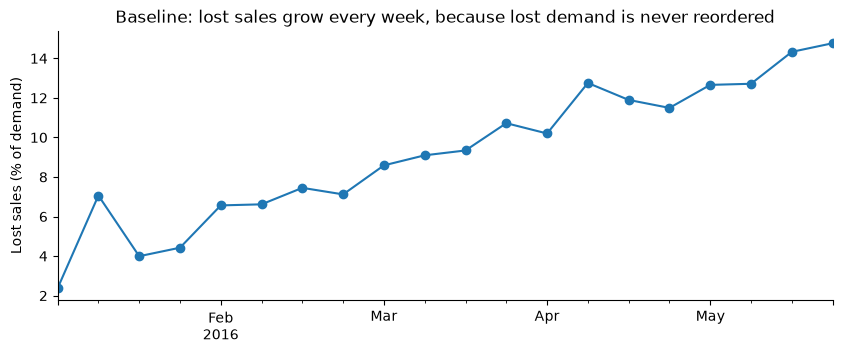

In [3]:
weekly = baseline.groupby(pd.Grouper(key="ds", freq="W-SUN"))[["demand", "lost"]].sum()

ax = (100 * weekly["lost"] / weekly["demand"]).plot(figsize=(10, 3.5), marker="o")
ax.set_title("Baseline: lost sales grow every week, because lost demand is never reordered")
ax.set_ylabel("Lost sales (% of demand)")
ax.set_xlabel("")
plt.show()

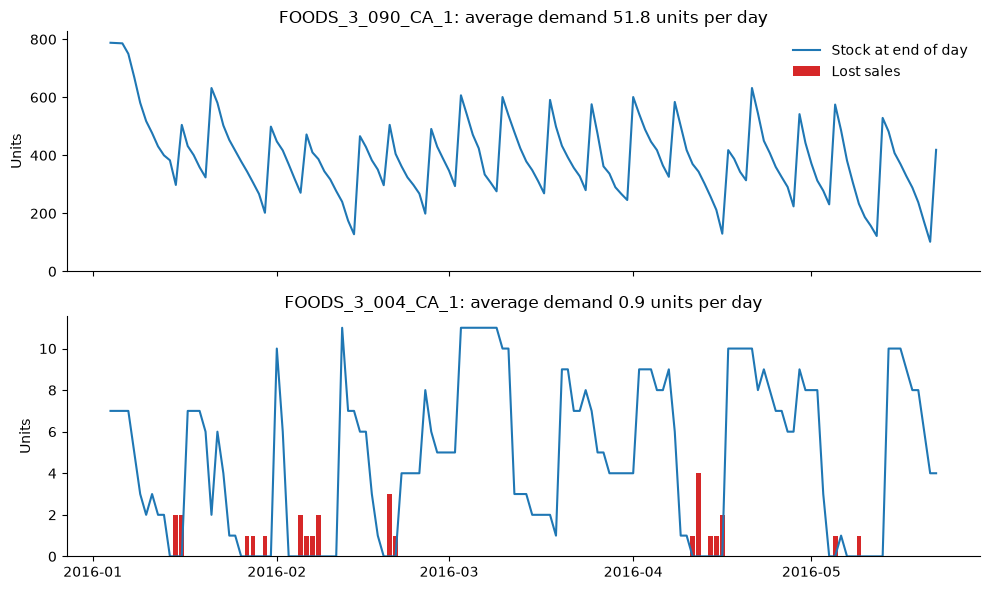

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for ax, uid in zip(axes, ["FOODS_3_090_CA_1", "FOODS_3_004_CA_1"]):
    g = baseline[baseline["unique_id"] == uid]
    ax.plot(g["ds"], g["end_stock"], label="Stock at end of day")
    ax.bar(g["ds"], g["lost"], color="tab:red", label="Lost sales")
    ax.set_title(f"{uid}: average demand {g['demand'].mean():.1f} units per day")
    ax.set_ylabel("Units")
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

In [ ]:
from src.inventory.kpis import scorecard
from src.inventory.policies import order_up_to_normal

normal = simulate(inputs, order_up_to_normal, lead_times)

compare = pd.concat(
    {"Baseline": scorecard(baseline), "(R, S) normal": scorecard(normal)}, names=["policy"]
)
compare.round(3)

In [ ]:
from src.inventory.policies import order_up_to_quantile, order_up_to_quantile_sum

quantile_sum = simulate(inputs, order_up_to_quantile_sum, lead_times)
quantile = simulate(inputs, order_up_to_quantile, lead_times)

compare = pd.concat(
    {
        "Baseline": scorecard(baseline),
        "(R, S) normal": scorecard(normal),
        "(R, S) sum of q95": scorecard(quantile_sum),
        "(R, S) quantile": scorecard(quantile),
    },
    names=["policy"],
)
compare.round(3)

In [ ]:
from functools import partial

from src.inventory.tuning import tune_z

z_by_class = tune_z(inputs, lead_times)
print(z_by_class)

tuned = simulate(inputs, partial(order_up_to_quantile, z_by_class=z_by_class), lead_times)

TEST_START = pd.Timestamp("2016-04-25")
test_window = pd.concat(
    {
        "Baseline": scorecard(baseline, TEST_START),
        "(R, S) normal": scorecard(normal, TEST_START),
        "(R, S) quantile": scorecard(quantile, TEST_START),
        "(R, S) quantile, tuned z": scorecard(tuned, TEST_START),
    },
    names=["policy"],
)
test_window.round(3)

In [ ]:
from src.inventory.policies import reorder_point

batch = simulate(inputs, partial(reorder_point, z_by_class=z_by_class), lead_times)

pd.concat(
    {"(R, S) quantile, tuned z": scorecard(tuned), "(s, S) tuned z": scorecard(batch)},
    names=["policy"],
).round(3)